<a href="https://colab.research.google.com/github/yolacin/LocalDispersion/blob/main/ToGitHub_MetroDataAnalysisAndCleanningFilling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Removed 7629 duplicate/conflicting rows.
Ratio of missing values: 0.0071


/tmp/ipykernel_3478/2976481629.py:48: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  total_expected_hours = len(pd.date_range(start=df.index.min(), end=df.index.max(), freq='H'))
/tmp/ipykernel_3478/2976481629.py:55: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='H')


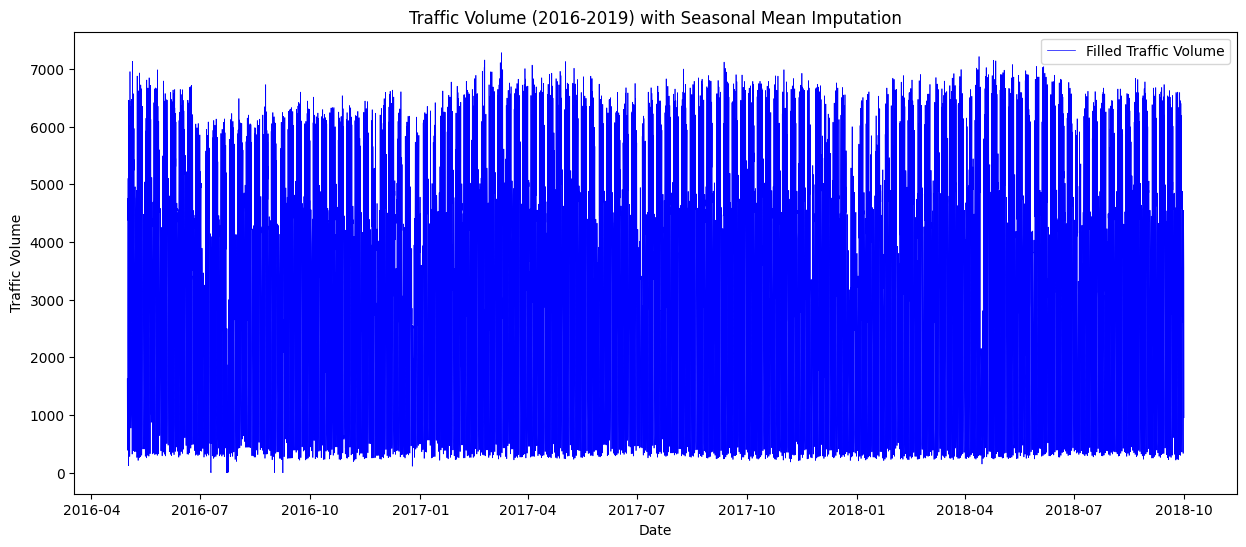

--- Final Cleaned Statistics ---
       traffic_volume
count    21192.000000
mean      3303.358265
std       1959.041428
min          0.000000
25%       1293.000000
50%       3502.500000
75%       4923.250000
max       7280.000000


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# 1. SETUP AND LOADING
# ---------------------------------------------------------
file_path = "file_path" # file path to data.
df = pd.read_csv(file_path)

# Selecting relevant columns as per your requirements
df = df[["date_time", "traffic_volume"]]

# 2. DATETIME CONVERSION AND CLEANING
# ---------------------------------------------------------
# Define column name for consistency
col_name = 'date_time'

# Convert to datetime format; use errors='coerce' to handle malformed strings
try:
    df[col_name] = pd.to_datetime(df[col_name], format='%d-%m-%Y %I:%M:%S %p')
except Exception:
    df[col_name] = pd.to_datetime(df[col_name])

# Drop any rows where date_time conversion failed (NaT)
df = df.dropna(subset=[col_name])

# Remove full-row duplicates and conflicting timestamps (keeping the first entry)
initial_rows = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset=[col_name], keep='first')
print(f"Removed {initial_rows - len(df)} duplicate/conflicting rows.")

# Sort and restrict data to the specific range requested
df = df.sort_values(by=col_name).set_index(col_name)
df = df.loc["2016-05-01":"2019-01-01"]

# 3. GAP ANALYSIS
# ---------------------------------------------------------
# Calculate time differences in hours [cite: 3, 4]
time_diffs = df.index.to_series().diff()
time_diff_hours = time_diffs.dt.total_seconds() / 3600

# Calculate missing value ratio based on the total timeline span
total_expected_hours = len(pd.date_range(start=df.index.min(), end=df.index.max(), freq='H'))
missing_count = total_expected_hours - len(df)
print(f"Ratio of missing values: {missing_count / total_expected_hours:.4f}")

# 4. REINDEXING AND CUSTOM FILLING
# ---------------------------------------------------------
# Create a continuous hourly index to expose missing rows as NaNs
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='H')
df_filled = df.reindex(full_range)

# Create helper columns for Day of Week (0=Mon, 6=Sun) and Hour (0-23)
df_filled['day_of_week'] = df_filled.index.dayofweek
df_filled['hour'] = df_filled.index.hour

# Calculate the mean traffic for each (Day of Week, Hour) combination
# This uses both past and future data relative to any specific missing point
seasonal_means = df_filled.groupby(['day_of_week', 'hour'])['traffic_volume'].mean()

# Apply the filling logic: if traffic_volume is NaN, use the calculated seasonal mean
df_filled['traffic_volume'] = df_filled.apply(
    lambda row: seasonal_means.loc[(row['day_of_week'], row['hour'])]
    if pd.isna(row['traffic_volume']) else row['traffic_volume'],
    axis=1
)

# Remove helper columns and finalize
df_final = df_filled.drop(columns=['day_of_week', 'hour'])

# 5. VISUALIZATION
# ---------------------------------------------------------
plt.figure(figsize=(15, 6))
plt.plot(df_final.index, df_final['traffic_volume'], color='blue', linewidth=0.5, label='Filled Traffic Volume')
plt.title('Traffic Volume (2016-2019) with Seasonal Mean Imputation')
plt.ylabel('Traffic Volume')
plt.xlabel('Date')
plt.legend()
plt.show()

# Display results
print("--- Final Cleaned Statistics ---")
print(df_final.describe())

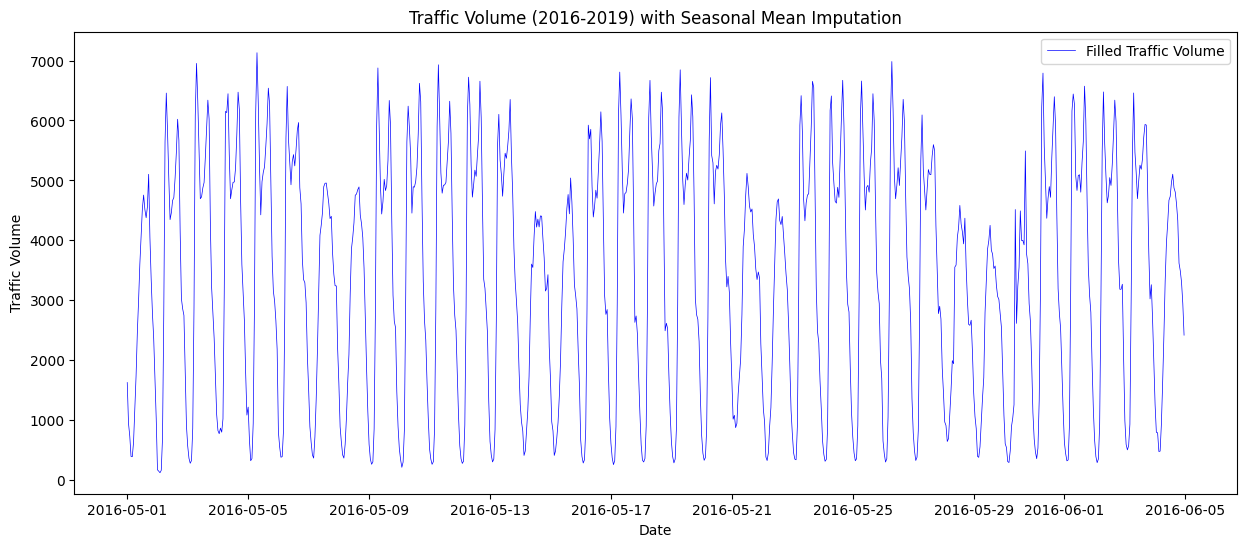

In [ ]:
# 5. VISUALIZATION
# ---------------------------------------------------------
plt.figure(figsize=(15, 6))
plt.plot(df_final.index[:35*24], df_final['traffic_volume'][:35*24], color='blue', linewidth=0.5, label='Filled Traffic Volume')
plt.title('Traffic Volume (2016-2019) with Seasonal Mean Imputation')
plt.ylabel('Traffic Volume')
plt.xlabel('Date')
plt.legend()
plt.show()

In [ ]:
path_to_save = "path_to_save" # path to save last verison of data.
df_final.to_csv(path_to_save)